# 01. DRAM 스펙과 셀 기본 물리 (D1)

설계는 **목표(스펙)를 먼저 정하는 것**에서 시작합니다. 이 노트북에서는
1. DRAM 셀이 데이터를 저장하고 잃는 원리를 보고,
2. 스펙 표를 정하고,
3. **슬라이더로 설계 값을 바꿔 가며** 스펙을 만족하는지 직접 확인합니다.

**실행 방법**: 메뉴에서 **런타임 → 모두 실행**.

> 모든 수치는 가정값과 시뮬레이션입니다. 실제 제품 값이 아닙니다. 사용한 가정은 맨 아래 표에 있습니다.

In [1]:
import os, sys, subprocess
BRANCH = "claude/feature-research"
REPO_URL = "https://github.com/tjrgns1753-create/dsadsa"
REPO_DIR = "/content/dsadsa"


def _sync_repo(repo_dir, url, branch):
    """저장소를 내려받거나 최신으로 맞춘다. 갱신에 실패해도 멈추지 않고 기존 코드로 계속한다."""
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", branch, url, repo_dir], check=True)
        return
    for cmd in (["git", "-C", repo_dir, "fetch", "-q", "--depth", "1", "origin", branch],
                ["git", "-C", repo_dir, "reset", "-q", "--hard", "FETCH_HEAD"]):
        if subprocess.run(cmd, capture_output=True).returncode != 0:
            print("경고: 최신 코드로 갱신하지 못해 기존 코드로 계속합니다 (" + " ".join(cmd[3:5]) + ")")
            return


if "google.colab" in sys.modules:
    _sync_repo(REPO_DIR, REPO_URL, BRANCH)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", REPO_DIR], check=True)
    if REPO_DIR not in sys.path:
        sys.path.insert(0, REPO_DIR)
    for _m in [m for m in sys.modules if m == "memdev" or m.startswith("memdev.")]:
        del sys.modules[_m]  # 갱신된 코드를 다시 불러오도록 이전에 불러온 모듈을 지운다
from memdev.colab import setup
status = setup(install=True)
print(status)

{'ngspice': True, 'devsim': True, 'korean_font': True}


## 1. 비유: 구멍 난 물컵

- DRAM 셀 하나 = **작은 물컵(커패시터 Cs)** 과 **수도꼭지(접근 트랜지스터)**
- 물 = 전하, 물 높이 = **셀 전압**. 가득(Vdd)이면 '1', 비면 '0'
- 컵에 아주 작은 구멍이 있어 물이 샙니다 → **누설 전류**

**읽을 때 일어나는 일 (전하 분배)**: 셀을 읽으면 컵의 물이 훨씬 큰 통(비트라인, Cbl)과 섞입니다.
비트라인은 미리 Vdd/2로 맞춰 두기 때문에, 셀이 '1'이면 비트라인 전압이 **아주 조금** 오릅니다.

$$\Delta V = (V_{cell} - V_{dd}/2)\cdot\frac{C_s}{C_s + C_{bl}}$$

센스앰프는 이 작은 신호(수십 mV)를 증폭해서 0/1을 판단합니다. 신호가 최소값보다 작으면 구분하지 못합니다.
그래서 셀 전압이 어떤 값(**읽기 실패 전압**) 아래로 떨어지면 데이터를 잃은 것입니다.

$$V_{fail} = V_{dd}/2 + \Delta V_{min}\cdot\frac{C_s + C_{bl}}{C_s}$$

## 2. 스펙 (D1)
현업에서는 설계 전에 이런 표를 먼저 정합니다. 아래 값은 출발점이 되는 **가정**입니다.

In [2]:
from memdev.dram.spec import DramSpec, evaluate_cell, spec_table

SPEC = DramSpec()
print(f"{'항목':8s} | {'목표':45s} | 의미")
for item, target, meaning in spec_table(SPEC):
    print(f"{item:8s} | {target:45s} | {meaning}")

항목       | 목표                                            | 의미
리텐션      | 85°C에서 64 ms 이상 (예비 셀 수리 후, 칩 기준)             | 리프레시 주기 안에 데이터 유지
읽기 신호    | 비트라인 신호 ≥ 50 mV                               | 센스앰프가 구분할 수 있는 최소 신호
쓰기       | 쓰기 펄스 10 ns 안에 셀 전압이 목표의 95% 도달               | 접근 트랜지스터가 충분히 켜짐
동작 조건    | 0~95°C, 전원 ±5%                                | 코너 검증 범위
수리 한도    | 가정 1000셀 (근거 미확인, D6 민감도)                     | 수율 판정 기준


## 3. 기준 설계에서 시간에 따른 셀 전압
기준 파라미터 세트 `dram_baseline`으로 온도별 셀 전압 감쇠와 리텐션을 계산합니다.

사용 중인 설계안: baseline (기준값에서 바꾼 항목: 없음)


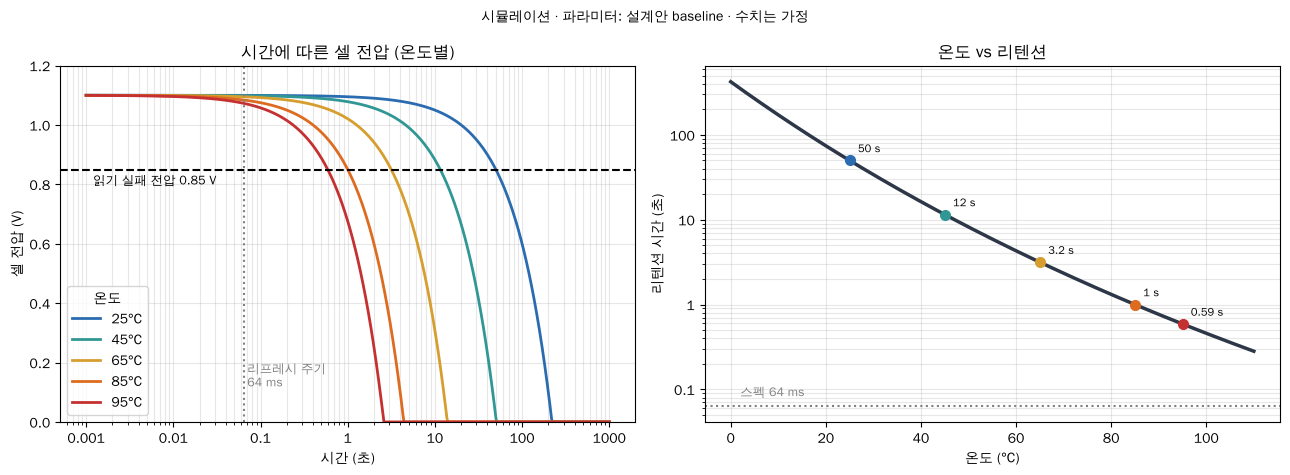

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from memdev.dram.cell import cell_voltage, fail_voltage, retention_time
from memdev.dram.leakage import arrhenius_leakage
from memdev.design import Design, changes_from_base, design_table, load_design, save_design
from memdev.plotting import plain_log_ticks, sim_label

DESIGN = load_design()
P = DESIGN.values()
print(f"사용 중인 설계안: {DESIGN.name} (기준값에서 바꾼 항목: {list(DESIGN.overrides) or '없음'})")
V_FAIL = fail_voltage(P["vdd"], P["cs"], P["cbl"], P["sense_min"])
TEMPS = [25, 45, 65, 85, 95]
COLORS = ["#2b6cb0", "#319795", "#d69e2e", "#dd6b20", "#c53030"]


def leak(temp_c, i_ref=P["i_leak_ref"], ea=P["ea"]):
    return arrhenius_leakage(temp_c, i_ref, P["t_ref_c"], ea)


t = np.logspace(-3, 3, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for temp, color in zip(TEMPS, COLORS):
    ax1.plot(t, cell_voltage(t, P["vdd"], leak(temp), P["cs"]), color=color, lw=2, label=f"{temp}°C")
ax1.axhline(V_FAIL, ls="--", color="black")
ax1.text(1.2e-3, V_FAIL - 0.05, f"읽기 실패 전압 {V_FAIL:.2f} V", fontsize=9)
ax1.axvline(P["t_refresh"], ls=":", color="gray")
ax1.text(P["t_refresh"] * 1.1, 0.12, "리프레시 주기\n64 ms", fontsize=9, color="gray")
ax1.set_xscale("log"); plain_log_ticks(ax1.xaxis)
ax1.set_ylim(0, 1.2)
ax1.set_xlabel("시간 (초)"); ax1.set_ylabel("셀 전압 (V)")
ax1.set_title("시간에 따른 셀 전압 (온도별)")
ax1.legend(title="온도"); ax1.grid(alpha=0.3, which="both")

temp_axis = np.linspace(0, 110, 200)
t_ret = retention_time(P["vdd"], V_FAIL, leak(temp_axis), P["cs"])
ax2.plot(temp_axis, t_ret, color="#2d3748", lw=2.5)
for temp, color in zip(TEMPS, COLORS):
    r = retention_time(P["vdd"], V_FAIL, leak(temp), P["cs"])
    ax2.plot(temp, r, "o", color=color, ms=7)
    ax2.annotate(f"{r:.2g} s", (temp, r), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax2.axhline(SPEC.retention_min_s, ls=":", color="gray")
ax2.text(2, SPEC.retention_min_s * 1.3, "스펙 64 ms", fontsize=9, color="gray")
ax2.set_yscale("log"); plain_log_ticks(ax2.yaxis)
ax2.set_xlabel("온도 (°C)"); ax2.set_ylabel("리텐션 시간 (초)")
ax2.set_title("온도 vs 리텐션"); ax2.grid(alpha=0.3, which="both")
fig.suptitle(sim_label(f"설계안 {DESIGN.name}"), fontsize=10)
fig.tight_layout()
plt.show()

**읽는 법**
- 왼쪽: 각 선이 검은 점선(읽기 실패 전압)과 만나는 시점이 그 온도의 리텐션 시간입니다.
- 오른쪽: 세로축이 10배씩 늘어나는 눈금입니다. 온도가 오르면 리텐션이 지수적으로 줄어드는데, 누설이 온도에 지수적으로
  민감하기 때문입니다(**아레니우스 법칙**). 10°C당 줄어드는 비율은 온도마다 다릅니다: 25→35°C에서 약 2.1배,
  80→90°C에서 약 1.7배(Ea 0.6 eV 가정). 그래서 이 그래프는 살짝 휘어 있고, 가로축을 온도 대신 **1/T(절대온도의 역수)**로
  그리면 정확히 직선이 됩니다.

## 4. 직접 바꿔 보기 (슬라이더)

| 슬라이더 | 뜻 | 늘리면 |
|---|---|---|
| Cs | 셀 커패시터 (컵 크기) | 물이 많아 오래 버팀, 신호도 커짐 |
| Cbl | 비트라인 커패시턴스 (큰 통) | 신호가 묽어져 작아짐 |
| 누설 @85°C | 85°C에서 구멍 크기 | 빨리 샘 |
| 온도 | 동작 온도 | 누설이 지수적으로 증가 |
| Ea | 활성화 에너지 (온도 민감도) | 온도에 더 민감 |
| 최소 신호 | 센스앰프가 구분하는 최소 신호 | 읽기 실패 전압이 올라감 |

슬라이더를 움직이면 아래 그래프와 판정이 바로 바뀝니다. (Colab에서 실행할 때 동작합니다.)

마음에 드는 설계를 찾았으면 **[현재 설계안으로 저장]** 을 누르세요. 다음 단계 노트북들이 이 설계안을 씁니다.
온도 슬라이더는 설계 값이 아니라 동작 조건이라 저장하지 않습니다.
Colab 런타임이 초기화되면 저장한 설계안도 사라지니, 남겨 두려면 **[설계안 파일 내려받기]** 를 누르세요.

In [4]:
import ipywidgets as w
from IPython.display import display


def explore(cs_fF=10.0, cbl_fF=50.0, leak85_fA=2.5, temp_c=85, ea_eV=0.6, sense_mV=50):
    cs, cbl, vdd = cs_fF * 1e-15, cbl_fF * 1e-15, P["vdd"]
    i_ref = leak85_fA * 1e-15
    ev = evaluate_cell(cs=cs, cbl=cbl, vdd=vdd, sense_min=sense_mV * 1e-3, i_ref=i_ref,
                       t_ref_c=P["t_ref_c"], ea_ev=ea_eV, temp_c=temp_c, spec=SPEC)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t, cell_voltage(t, vdd, leak(temp_c, i_ref, ea_eV), cs), lw=2.5, color="#2b6cb0")
    if ev.v_fail < 1.2:
        ax.axhline(ev.v_fail, ls="--", color="black")
    ax.axvline(SPEC.retention_min_s, ls=":", color="gray")
    ax.set_xscale("log"); plain_log_ticks(ax.xaxis)
    ax.set_ylim(0, 1.2)
    ax.set_xlabel("시간 (초)"); ax.set_ylabel("셀 전압 (V)")
    ax.set_title(f"{temp_c}°C에서 셀 전압 · " + sim_label(f"설계안 {DESIGN.name} + 슬라이더"), fontsize=9)
    ax.grid(alpha=0.3, which="both")
    plt.show()

    def verdict(r):
        return f"{'통과' if r.passed else '실패'} (여유 {r.margin:.2g}배)"

    if not ev.readable:
        print(f"읽기 불가: 가득 찬 셀의 신호 {ev.signal_v * 1e3:.1f} mV가 최소 감지값 {sense_mV} mV보다 작습니다.")
    print(f"읽기 실패 전압: {ev.v_fail:.3f} V,  가득 찬 셀의 신호: {ev.signal_v * 1e3:.1f} mV"
          f" → 읽기 신호 (최소 {sense_mV} mV 기준) {verdict(ev.signal)}")
    print(f"{temp_c}°C 리텐션: {ev.retention_now_s:.3g} s")
    print(f"스펙 조건({SPEC.retention_temp_c:g}°C) 리텐션: {ev.retention_spec_s:.3g} s"
          f" → 리텐션 스펙 {verdict(ev.retention)}")


ui = w.interactive(
    explore,
    cs_fF=w.FloatSlider(value=P["cs"] * 1e15, min=2, max=30, step=1, description="Cs (fF)"),
    cbl_fF=w.FloatSlider(value=P["cbl"] * 1e15, min=10, max=200, step=5, description="Cbl (fF)"),
    leak85_fA=w.FloatLogSlider(value=P["i_leak_ref"] * 1e15, base=10, min=-1, max=2,
                               description="누설@85°C (fA)"),
    temp_c=w.IntSlider(value=85, min=0, max=110, step=5, description="온도 (°C)"),
    ea_eV=w.FloatSlider(value=P["ea"], min=0.3, max=1.2, step=0.05, description="Ea (eV)"),
    sense_mV=w.IntSlider(value=round(P["sense_min"] * 1e3), min=20, max=150, step=5,
                         description="최소 신호 (mV)"),
)

# 슬라이더 이름 → (파라미터 이름, 단위 변환)
SLIDER_TO_PARAM = {"cs_fF": ("cs", 1e-15), "cbl_fF": ("cbl", 1e-15), "leak85_fA": ("i_leak_ref", 1e-15),
                   "ea_eV": ("ea", 1.0), "sense_mV": ("sense_min", 1e-3)}
name_box = w.Text(value=DESIGN.name if DESIGN.overrides else "my_design", description="설계안 이름")
save_btn = w.Button(description="현재 설계안으로 저장", button_style="primary")
reset_btn = w.Button(description="기준값으로 되돌리기")
download_btn = w.Button(description="설계안 파일 내려받기")
msg = w.Output()


def on_save(_):
    with msg:
        msg.clear_output()
        slider_values = {param: ui.kwargs[k] * scale for k, (param, scale) in SLIDER_TO_PARAM.items()}
        design = Design(name=name_box.value.strip() or "my_design",
                        overrides=changes_from_base(slider_values))
        path = save_design(design)
        print(f"저장했습니다: {design.name} (바꾼 항목: {list(design.overrides) or '없음'}) → {path}")
        print("다음 노트북은 이 설계안을 씁니다. 이 노트북 위쪽 그래프에 반영하려면 '런타임 → 모두 실행'을 누르세요.")


def on_reset(_):
    with msg:
        msg.clear_output()
        save_design(Design(name="baseline"))
        print("기준 설계안으로 되돌렸습니다. '런타임 → 모두 실행'을 누르면 슬라이더도 기준값으로 돌아갑니다.")


def on_download(_):
    with msg:
        msg.clear_output()
        path = save_design(load_design())
        try:
            from google.colab import files
            files.download(str(path))
        except ImportError:
            print(f"Colab이 아니므로 파일 위치만 알려 드립니다: {path}")


save_btn.on_click(on_save)
reset_btn.on_click(on_reset)
download_btn.on_click(on_download)
display(ui, w.HBox([name_box, save_btn, reset_btn, download_btn]), msg)

interactive(children=(FloatSlider(value=10.0, description='Cs (fF)', max=30.0, min=2.0, step=1.0), FloatSlider…

Output()

## 5. 이상한 점: 1초를 버티는데 왜 64 ms마다 리프레시할까?

기준 셀은 85°C에서 약 **1초**를 버팁니다. 스펙(64 ms)보다 15배 이상 여유가 있습니다.
그런데 실제 DRAM은 64 ms마다 리프레시합니다.

이 그래프는 **평범한 셀 하나**이기 때문입니다. 칩에는 셀이 수십억 개 있고, 공정 편차 때문에 **일부는 훨씬 빨리 새는 약한 셀**입니다.
리프레시 주기는 평균이 아니라 **가장 약한 셀**에 맞춰야 합니다.
→ M5(산포와 수율)에서 셀 수백만 개를 만들어 이 꼬리를 직접 다루고, M6에서 결론 질문(약한 셀이 있는 행만 자주 리프레시하기)에 답합니다.

## 6. 면접에서 이렇게 말할 수 있습니다

> "DRAM 셀은 커패시터에 저장한 전하가 누설로 빠져나가서, 읽을 때 비트라인과 전하를 나눈 신호가 센스앰프의 최소 감지값 아래로 떨어지기 전에 리프레시해야 합니다.
> 신호 크기는 Cs/(Cs+Cbl) 비에 비례해서 Cs가 작아지면 리텐션과 신호가 함께 나빠집니다.
> 누설은 온도에 지수적으로 증가해 고온에서 리텐션이 급격히 짧아지고, 리프레시 주기는 평균 셀이 아니라 분포 꼬리의 약한 셀이 정합니다."

## 7. 사용한 가정

In [5]:
from IPython.display import Markdown


def fmt(x):
    return f"{x:.3g}"


lines = [f"설계안 **{DESIGN.name}** · 굵은 글씨는 기준값에서 바꾼 항목", "",
         "| 항목 | 기준값 | 현재 설계안 | 단위 | 상태 | 출처 |", "|---|---|---|---|---|---|"]
for r in design_table(DESIGN):
    cur = f"**{fmt(r.current)}**" if r.changed else fmt(r.current)
    lines.append(f"| {r.key} | {fmt(r.base)} | {cur} | {r.unit} | {r.status} | {r.source} |")
display(Markdown("\n".join(lines)))

설계안 **baseline** · 굵은 글씨는 기준값에서 바꾼 항목

| 항목 | 기준값 | 현재 설계안 | 단위 | 상태 | 출처 |
|---|---|---|---|---|---|
| cs | 1e-14 | 1e-14 | F | assumed | 시험작 가정값, 공개 자료 확인 전 |
| cbl | 5e-14 | 5e-14 | F | assumed | 시험작 가정값, 공개 자료 확인 전 |
| vdd | 1.1 | 1.1 | V | assumed | 시험작 가정값, 공개 자료 확인 전 |
| sense_min | 0.05 | 0.05 | V | assumed | 시험작 가정값, 공개 자료 확인 전 |
| i_leak_ref | 2.5e-15 | 2.5e-15 | A | assumed | 시험작 가정값, 공개 자료 확인 전 (t_ref_c에서의 셀 누설) |
| t_ref_c | 85 | 85 | degC | assumed | 시험작 가정값, 공개 자료 확인 전 |
| ea | 0.6 | 0.6 | eV | assumed | 시험작 가정값, 공개 자료 확인 전 |
| t_refresh | 0.064 | 0.064 | s | assumed | 시험작 가정값, 공개 자료 확인 전 |
| write_pulse | 1e-08 | 1e-08 | s | assumed | 시험작 가정값, 공개 자료 확인 전 |
| repair_limit | 1e+03 | 1e+03 | cells | assumed | 근거 미확인 가정값, D6에서 민감도로 다룸 |